In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv("/content/weather_classification_data.csv")

In [ ]:
print(df)

       Temperature  Humidity  Wind Speed  Precipitation (%)    Cloud Cover  \
0             14.0        73         9.5               82.0  partly cloudy   
1             39.0        96         8.5               71.0  partly cloudy   
2             30.0        64         7.0               16.0          clear   
3             38.0        83         1.5               82.0          clear   
4             27.0        74        17.0               66.0       overcast   
...            ...       ...         ...                ...            ...   
13195         10.0        74        14.5               71.0       overcast   
13196         -1.0        76         3.5               23.0         cloudy   
13197         30.0        77         5.5               28.0       overcast   
13198          3.0        76        10.0               94.0       overcast   
13199         -5.0        38         0.0               92.0       overcast   

       Atmospheric Pressure  UV Index  Season  Visibility (km) 

In [ ]:
df.head()

,Temperature,Humidity,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,Weather Type
0,14.0,73,9.5,82.0,partly cloudy,1010.82,2,Winter,3.5,inland,Rainy
1,39.0,96,8.5,71.0,partly cloudy,1011.43,7,Spring,10.0,inland,Cloudy
2,30.0,64,7.0,16.0,clear,1018.72,5,Spring,5.5,mountain,Sunny
3,38.0,83,1.5,82.0,clear,1026.25,7,Spring,1.0,coastal,Sunny
4,27.0,74,17.0,66.0,overcast,990.67,1,Winter,2.5,mountain,Rainy


In [ ]:
df.shape

(13200, 11)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13200 entries, 0 to 13199
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Temperature           13200 non-null  float64
 1   Humidity              13200 non-null  int64  
 2   Wind Speed            13200 non-null  float64
 3   Precipitation (%)     13200 non-null  float64
 4   Cloud Cover           13200 non-null  object 
 5   Atmospheric Pressure  13200 non-null  float64
 6   UV Index              13200 non-null  int64  
 7   Season                13200 non-null  object 
 8   Visibility (km)       13200 non-null  float64
 9   Location              13200 non-null  object 
 10  Weather Type          13200 non-null  object 
dtypes: float64(5), int64(2), object(4)
memory usage: 1.1+ MB


In [ ]:
df.describe()

,Temperature,Humidity,Wind Speed,Precipitation (%),Atmospheric Pressure,UV Index,Visibility (km)
count,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000,13200.000000
mean,19.127576,68.710833,9.832197,53.644394,1005.827896,4.005758,5.462917
std,17.386327,20.194248,6.908704,31.946541,37.199589,3.856600,3.371499
min,-25.000000,20.000000,0.000000,0.000000,800.120000,0.000000,0.000000
25%,4.000000,57.000000,5.000000,19.000000,994.800000,1.000000,3.000000
50%,21.000000,70.000000,9.000000,58.000000,1007.650000,3.000000,5.000000
75%,31.000000,84.000000,13.500000,82.000000,1016.772500,7.000000,7.500000
max,109.000000,109.000000,48.500000,109.000000,1199.210000,14.000000,20.000000


In [ ]:
df.isnull().sum()

,0
Temperature,0
Humidity,0
Wind Speed,0
Precipitation (%),0
Cloud Cover,0
Atmospheric Pressure,0
UV Index,0
Season,0
Visibility (km),0
Location,0


In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
for column in df.columns:
    if df[column].dtype == 'object':
        df[column] = df[column].fillna(df[column].mode()[0])
    else:
        df[column] = df[column].fillna(df[column].median())

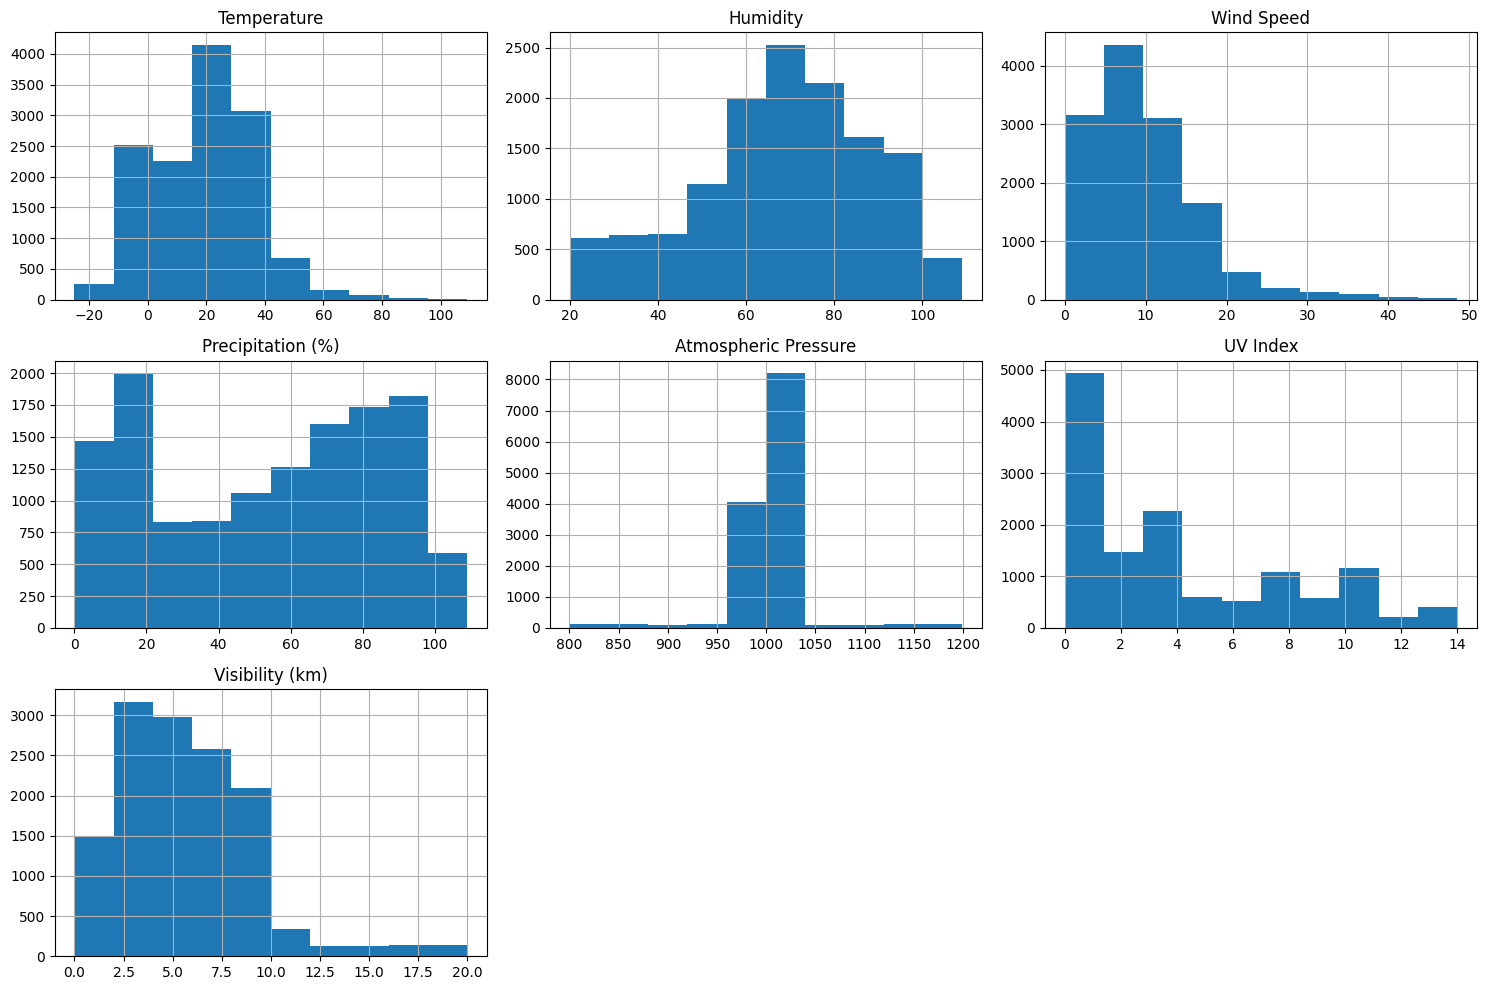

In [ ]:
df.hist(figsize=(15,10))
plt.tight_layout()
plt.show()

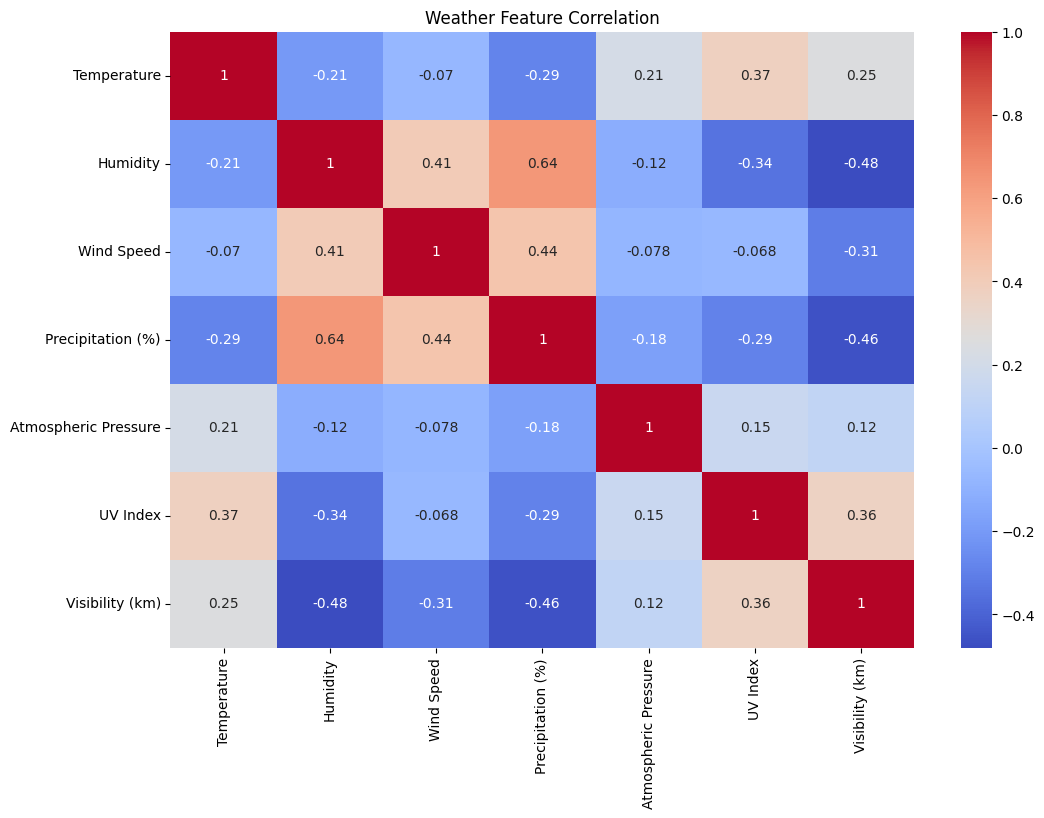

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12,8))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title("Weather Feature Correlation")
plt.show()

Weather Type
Rainy     3300
Cloudy    3300
Sunny     3300
Snowy     3300
Name: count, dtype: int64


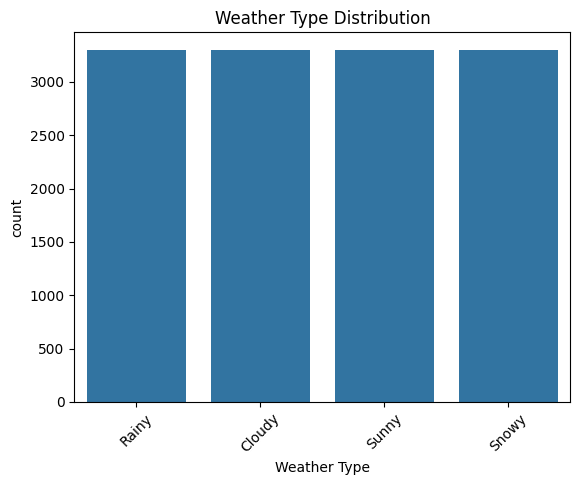

In [ ]:
print(df['Weather Type'].value_counts())

sns.countplot(data=df, x='Weather Type')
plt.title("Weather Type Distribution")
plt.xticks(rotation=45)
plt.show()

In [ ]:
df_encoded = df.copy()

encoders = {}

for column in df_encoded.select_dtypes(include='object').columns:
    encoders[column] = LabelEncoder()
    df_encoded[column] = encoders[column].fit_transform(
        df_encoded[column]
    )

In [ ]:
X = df_encoded.drop('Weather Type', axis=1)
y = df_encoded['Weather Type']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree Accuracy:",
      accuracy_score(y_test, dt_pred)*100)

Decision Tree Accuracy: 90.6060606060606


In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred)*100)

Random Forest Accuracy: 91.51515151515152


In [ ]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

knn_pred = knn_model.predict(X_test_scaled)

print("KNN Accuracy:",
      accuracy_score(y_test, knn_pred)*100)

KNN Accuracy: 89.88636363636363


In [ ]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_pred)*100)

Logistic Regression Accuracy: 85.45454545454545


In [ ]:
results = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Random Forest',
        'KNN',
        'Logistic Regression'
    ],
    'Accuracy': [
        accuracy_score(y_test, dt_pred)*100,
        accuracy_score(y_test, rf_pred)*100,
        accuracy_score(y_test, knn_pred)*100,
        accuracy_score(y_test, lr_pred)*100
    ]
})

print(results)

                 Model   Accuracy
0        Decision Tree  90.606061
1        Random Forest  91.515152
2                  KNN  89.886364
3  Logistic Regression  85.454545


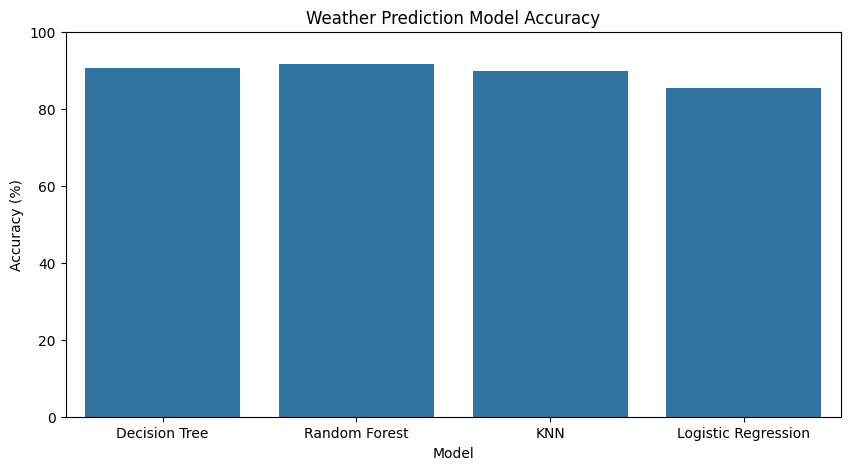

In [ ]:
plt.figure(figsize=(10,5))

sns.barplot(data=results, x='Model', y='Accuracy')

plt.title("Weather Prediction Model Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.show()

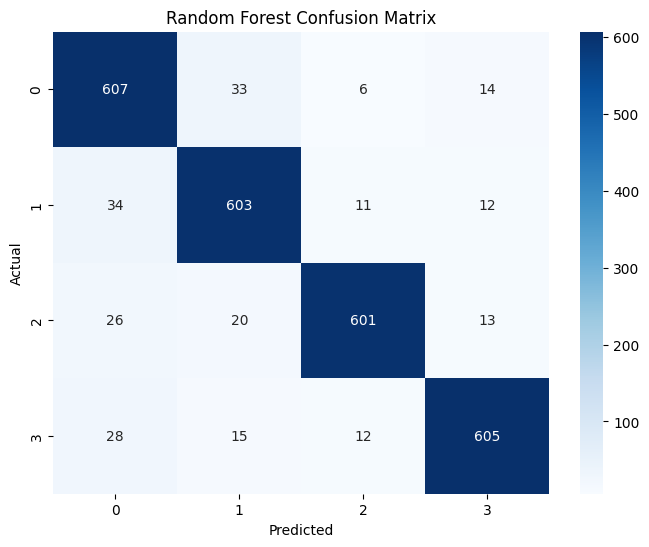

In [ ]:
plt.figure(figsize=(8,6))

sns.heatmap(
    confusion_matrix(y_test, rf_pred),
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.87      0.92      0.90       660
           1       0.90      0.91      0.91       660
           2       0.95      0.91      0.93       660
           3       0.94      0.92      0.93       660

    accuracy                           0.92      2640
   macro avg       0.92      0.92      0.92      2640
weighted avg       0.92      0.92      0.92      2640



In [ ]:
import joblib

joblib.dump(rf_model, 'weather_prediction_model.pkl')
joblib.dump(scaler, 'weather_scaler.pkl')
joblib.dump(encoders, 'weather_encoders.pkl')

print("Models saved successfully!")

Models saved successfully!


In [ ]:
print("🌤️ WEATHER PREDICTION SYSTEM")

input_data = {}

for column in X.columns:
    if column in encoders:
        options = list(encoders[column].classes_)
        print("\n", column, "Options:", options)
        value = input("Enter " + column + ": ").strip()

        # Find a case-insensitive match
        matched_value = None
        for option in options:
            if option.lower() == value.lower():
                matched_value = option
                break

        if matched_value is None:
            raise ValueError("Invalid category entered!")

        input_data[column] = encoders[column].transform([matched_value])[0]

    else:
        input_data[column] = float(
            input("Enter " + column + ": ")
        )

input_df = pd.DataFrame([input_data])

prediction = rf_model.predict(input_df)

predicted_weather = encoders['Weather Type'].inverse_transform(
    prediction
)[0]

print("\n🌤️ PREDICTED WEATHER:", predicted_weather)

🌤️ WEATHER PREDICTION SYSTEM
Enter Temperature: 14.0
Enter Humidity: 73
Enter Wind Speed: 9.5
Enter Precipitation (%): 82.0

 Cloud Cover Options: ['clear', 'cloudy', 'overcast', 'partly cloudy']
Enter Cloud Cover: partly cloudy
Enter Atmospheric Pressure: 1010.82
Enter UV Index: 2

 Season Options: ['Autumn', 'Spring', 'Summer', 'Winter']
Enter Season: Winter
Enter Visibility (km): 3.5

 Location Options: ['coastal', 'inland', 'mountain']
Enter Location: inland

🌤️ PREDICTED WEATHER: Rainy


In [ ]:
!pip install streamlit pyngrok -q

In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="Weather Prediction",
    page_icon="🌦️",
    layout="centered"
)

model = joblib.load("weather_prediction_model.pkl")
scaler = joblib.load("weather_scaler.pkl")
encoders = joblib.load("weather_encoders.pkl")

st.title("🌦️ Weather Prediction System")
st.write("Predict weather using Machine Learning")

st.divider()

st.subheader("Enter Weather Details")

weather_inputs = {}

for column in model.feature_names_in_:

    if column in encoders:

        options = list(encoders[column].classes_)

        weather_inputs[column] = st.selectbox(
            column,
            options
        )

    else:

        weather_inputs[column] = st.number_input(
            column,
            value=25.0
        )

if st.button("Predict Weather", use_container_width=True):

    input_df = pd.DataFrame([weather_inputs])

    for column in input_df.columns:

        if column in encoders:
            input_df[column] = encoders[column].transform(
                input_df[column]
            )

    prediction = model.predict(input_df)

    result = encoders['Weather Type'].inverse_transform(
        prediction
    )[0]

    st.divider()

    st.success("Weather Prediction Completed!")

    st.subheader("Predicted Weather")

    if result == "Sunny":
        st.markdown("# ☀️ Sunny")

    elif result == "Rainy":
        st.markdown("# 🌧️ Rainy")

    elif result == "Cloudy":
        st.markdown("# ☁️ Cloudy")

    elif result == "Snowy":
        st.markdown("# ❄️ Snowy")

    else:
        st.markdown(f"# 🌤️ {result}")

    st.balloons()

Writing app.py


In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("YOUR_AUTH_TOKEN")

public_url = ngrok.connect(8501)

print("YOUR WEATHER PREDICTION WEBSITE")

In [ ]:
!streamlit run app.py --server.port 8501 > streamlit.log 2>&1 &

In [ ]:
from pyngrok import ngrok

public_url = ngrok.connect(8501)

print("YOUR WEATHER PREDICTION WEBSITE:")
print(public_url)

YOUR WEATHER PREDICTION WEBSITE:
NgrokTunnel: "https://puzzling-giggling-engraved.ngrok-free.dev" -> "http://localhost:8501"
